All labeled: 31,460 | clean: 23,028
Band lower bounds: {'Failed': 0.0, 'Serious': 10.0, 'Very Poor': 25.0, 'Poor': 40.0, 'Fair': 55.0, 'Satisfactory': 70.0, 'Good': 85.0}


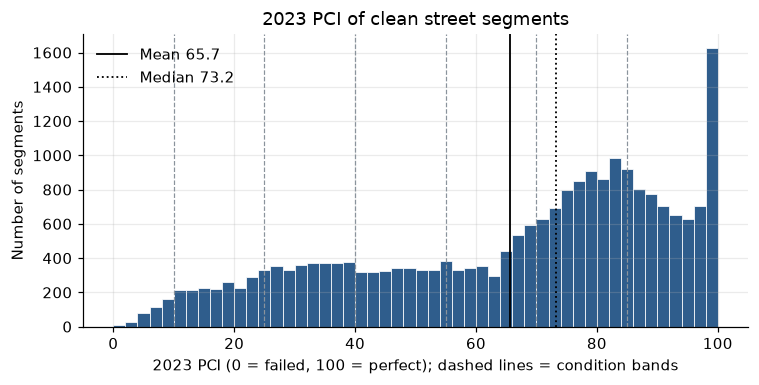

{'count': 23028.0, 'mean': 65.7, 'std': 25.9, 'min': 0.0, '25%': 45.3, '50%': 73.2, '75%': 86.3, 'max': 100.0}
Skewness: -0.6


In [1]:
# EDA Cell 1 — Setup + Figure 1: distribution of the label (2023 PCI) on clean segments
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.home() / "pavement_index"
PROC, FIG = ROOT / "data" / "processed", ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROC / "segments_clean.csv")
clean = df[df["in_clean_set"] == 1].copy()
print(f"All labeled: {len(df):,} | clean: {len(clean):,}")

# Consistent, quiet styling for every report figure
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, GRAY = "#2F5D8C", "#8A939C"

# Band boundaries = lowest PCI observed in each band (skip the lowest band)
band_min = df.groupby("pci23_d")["pci23"].min().sort_values()
print("Band lower bounds:", band_min.round(0).to_dict())

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(clean["pci23"], bins=np.arange(0, 102, 2), color=BLUE, edgecolor="white", linewidth=0.5)
for b in band_min.iloc[1:].values:
    ax.axvline(b, color=GRAY, lw=0.8, ls="--")
ax.axvline(clean["pci23"].mean(), color="black", lw=1.2, label=f"Mean {clean['pci23'].mean():.1f}")
ax.axvline(clean["pci23"].median(), color="black", lw=1.2, ls=":", label=f"Median {clean['pci23'].median():.1f}")
ax.set(xlabel="2023 PCI (0 = failed, 100 = perfect); dashed lines = condition bands",
       ylabel="Number of segments", title="2023 PCI of clean street segments")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig1_pci_distribution.png", dpi=200)
plt.show()

print(clean["pci23"].describe().round(1).to_dict())
print("Skewness:", round(clean["pci23"].skew(), 2))

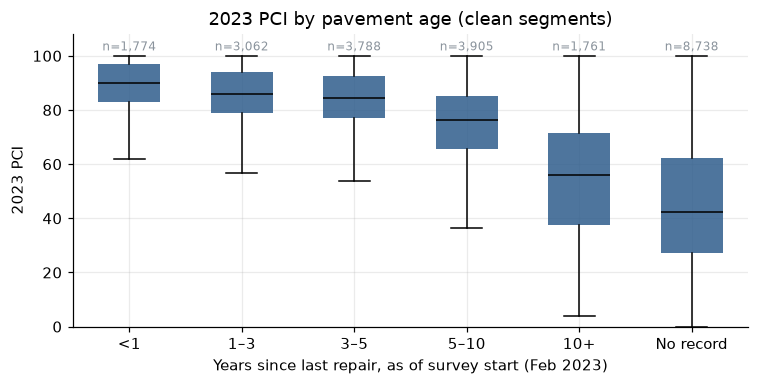

           count  median  mean
age_group                     
<1          1774    90.0  88.7
1–3         3062    86.0  85.7
3–5         3788    84.3  83.5
5–10        3905    76.2  72.7
10+         1761    56.0  54.3
No record   8738    42.5  45.5

Spearman (years since repair vs PCI): -0.52

Segments at PCI 100: 1,195; age-group share (%):
age_group
<1           23.5
1–3          28.5
3–5          24.5
5–10         11.0
10+           2.1
No record    10.4


In [2]:
# EDA Cell 2 — Figure 2: PCI by pavement age (years since last pre-survey repair)
bins, labels = [0, 1, 3, 5, 10, 30], ["<1", "1–3", "3–5", "5–10", "10+"]
clean["age_group"] = pd.cut(clean["years_since_repair"], bins=bins, labels=labels, right=False).astype(str)
clean.loc[clean["has_prior_repair"] == 0, "age_group"] = "No record"
order = labels + ["No record"]
groups = [clean.loc[clean["age_group"] == g, "pci23"] for g in order]

fig, ax = plt.subplots(figsize=(7, 3.6))
bp = ax.boxplot(groups, tick_labels=order, patch_artist=True, showfliers=False,
                medianprops=dict(color="black"), widths=0.55)
for box in bp["boxes"]:
    box.set(facecolor=BLUE, alpha=0.85, edgecolor="none")
for i, g in enumerate(groups, 1):
    ax.text(i, 102, f"n={len(g):,}", ha="center", fontsize=8, color=GRAY)
ax.set(ylim=(0, 108), xlabel="Years since last repair, as of survey start (Feb 2023)",
       ylabel="2023 PCI", title="2023 PCI by pavement age (clean segments)")
fig.tight_layout()
fig.savefig(FIG / "fig2_pci_by_pavement_age.png", dpi=200)
plt.show()

print(clean.groupby("age_group")["pci23"].agg(["count", "median", "mean"]).reindex(order).round(1))
rho = clean[["years_since_repair", "pci23"]].dropna().corr(method="spearman").iloc[0, 1]
print(f"\nSpearman (years since repair vs PCI): {rho:.2f}")

top = clean[clean["pci23"] >= 99.5]
print(f"\nSegments at PCI 100: {len(top):,}; age-group share (%):")
print(top["age_group"].value_counts(normalize=True).mul(100).round(1).reindex(order).to_string())

### Checkpoint 3 — The label and its strongest metadata predictor

- **Label distribution (Fig. 1):** clean-segment PCI has mean 65.7, median 73.2, SD 25.9, skew −0.6:
  a broad tail of deteriorated streets (PCI 10–60) and a peak of healthy streets (75–90). Band edges
  in the data (10/25/40/55/70/85) match the standard ASTM D6433 bands. 1,195 segments sit at the
  ceiling of 100, so predictions should be clipped to 0–100 and MAE is the primary metric.
- **Pavement age (Fig. 2):** PCI declines with years since the last pre-survey repair (Spearman −0.52).
  Medians: 90.0 (<1 yr), 86.0 (1–3), 84.3 (3–5), 76.2 (5–10), 56.0 (10+).
- **"No record" is informative:** the 8,738 clean segments (38%) with no repair on file have the lowest
  median PCI (42.5). Missingness here is not random, so it is encoded as its own flag rather than imputed.
- **Ceiling explained:** 76.5% of PCI-100 segments were repaired within 5 years before the survey;
  10.4% have no record, suggesting the repair log is incomplete (e.g., private or utility work).
- **Modeling consequence:** pavement age is a strong, cheap predictor, so the metadata-only baseline
  is a demanding benchmark the image model must beat (H2).

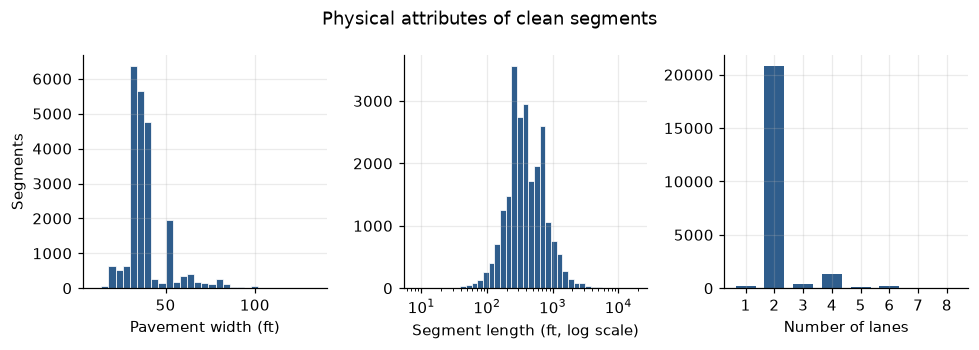

                        n  spearman_vs_pci
feature                                   
has_prior_repair    23028            0.594
years_since_repair  14290           -0.516
pav_length          23028           -0.100
pwidth              23027            0.048
is_residential      23023            0.045
lane_no             23023           -0.040


In [4]:
# EDA Cell 3 — Figure 3: physical attributes + Spearman correlation of each feature with PCI
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
axes[0].hist(clean["pwidth"].dropna(), bins=np.arange(10, 135, 4), color=BLUE, edgecolor="white", lw=0.5)
axes[0].set(xlabel="Pavement width (ft)", ylabel="Segments")
axes[1].hist(clean["pav_length"], bins=np.logspace(np.log10(8), np.log10(clean["pav_length"].max()), 40),
             color=BLUE, edgecolor="white", lw=0.5)
axes[1].set_xscale("log")
axes[1].set(xlabel="Segment length (ft, log scale)")
lane_counts = clean["lane_no"].value_counts().sort_index()
axes[2].bar(lane_counts.index.astype(int).astype(str), lane_counts.values, color=BLUE, width=0.7)
axes[2].set(xlabel="Number of lanes")
fig.suptitle("Physical attributes of clean segments")
fig.tight_layout()
fig.savefig(FIG / "fig3_physical_attributes.png", dpi=200)
plt.show()

# Rank correlation of each candidate metadata feature with the label
feats = ["pwidth", "pav_length", "lane_no", "years_since_repair", "has_prior_repair", "is_residential"]
rows = []
for f in feats:
    s = clean[[f, "pci23"]].dropna()
    rows.append((f, len(s), s.corr(method="spearman").iloc[0, 1]))
corr_tbl = pd.DataFrame(rows, columns=["feature", "n", "spearman_vs_pci"]).set_index("feature").round(3)
print(corr_tbl.sort_values("spearman_vs_pci", key=abs, ascending=False))
corr_tbl.to_csv(PROC / "eda_feature_pci_spearman.csv")

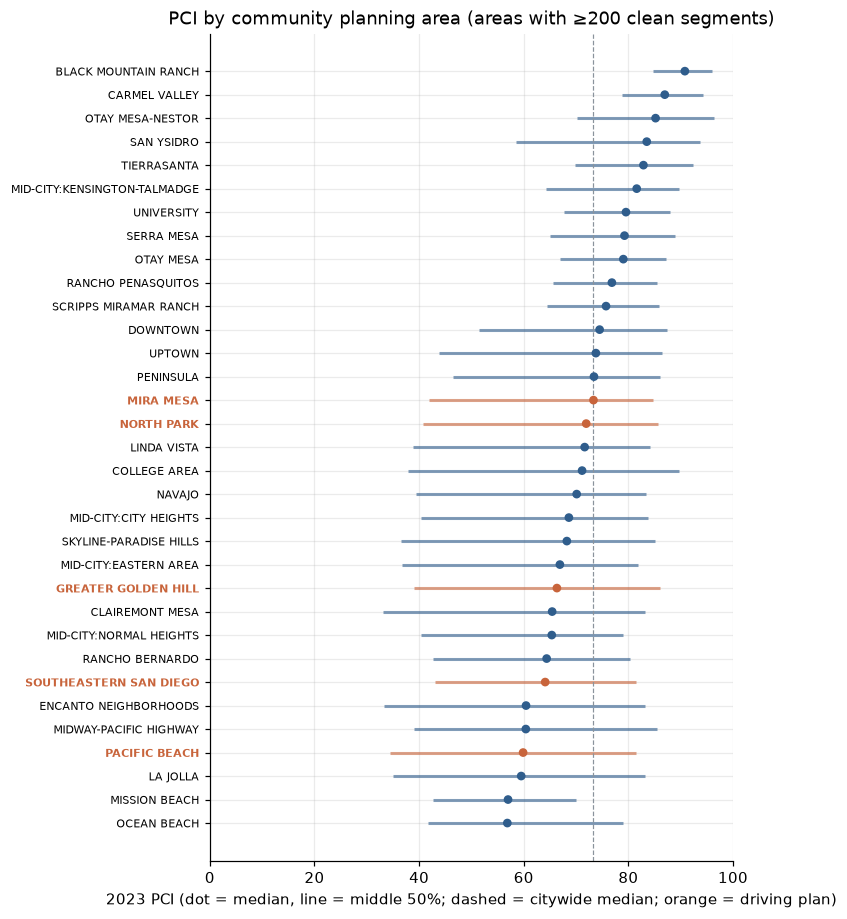

Areas shown: 33 of 57 | eta² (area explains PCI variance): 0.092
Median range across shown areas: 56.9 to 90.8

Drive areas (clean residential segments):
                        clean_res_n  median_pci   iqr  pct_poor_or_worse  bands_with_20plus  median_block_ft  stale_pct  residential_pct
MIRA MESA                    1157.0        74.0  45.1               33.1                7.0            292.5       22.8             89.5
PACIFIC BEACH                 871.0        58.1  47.2               47.2                6.0            486.3       18.3             92.6
NORTH PARK                    829.0        73.3  41.2               32.2                6.0            382.0       27.3             95.1
GREATER GOLDEN HILL           320.0        66.1  47.0               40.3                6.0            379.0       24.4             99.3
SOUTHEASTERN SAN DIEGO        887.0        63.4  39.4               39.7                6.0            382.0       26.5             95.0

Names not found in data

In [7]:
# EDA Cell 4 — Figure 4: PCI by planning area, driving-plan highlight, and drive-area summary

# --- Driving plan: driven + planned areas (edit this list to change the highlight and table) ---
DRIVE_AREAS = ["MIRA MESA", "PACIFIC BEACH", "NORTH PARK", "GREATER GOLDEN HILL",
               "SOUTHEASTERN SAN DIEGO"]
ORANGE = "#C8643B"
MIN_N = 200

# --- Figure 4: median and middle-50% PCI per planning area (areas with >= MIN_N clean segments) ---
g = clean.groupby("cpname")["pci23"]
stats = pd.DataFrame({"n": g.size(), "q25": g.quantile(.25), "median": g.median(), "q75": g.quantile(.75)})
stats = stats[stats["n"] >= MIN_N].sort_values("median")
is_drive = stats.index.isin(DRIVE_AREAS)

fig, ax = plt.subplots(figsize=(7, 0.22 * len(stats) + 1.2))
y = np.arange(len(stats))
colors = np.where(is_drive, ORANGE, BLUE)
ax.hlines(y, stats["q25"], stats["q75"], color=colors, lw=2, alpha=0.6)
ax.scatter(stats["median"], y, color=colors, s=22, zorder=3)
ax.axvline(clean["pci23"].median(), color=GRAY, ls="--", lw=0.8)
ax.set_yticks(y, stats.index, fontsize=7.5)
for lbl, drive in zip(ax.get_yticklabels(), is_drive):
    if drive:
        lbl.set_color(ORANGE); lbl.set_fontweight("bold")
ax.set(xlim=(0, 100),
       xlabel="2023 PCI (dot = median, line = middle 50%; dashed = citywide median; orange = driving plan)",
       title=f"PCI by community planning area (areas with ≥{MIN_N} clean segments)")
fig.tight_layout()
fig.savefig(FIG / "fig4_pci_by_planning_area.png", dpi=200)
plt.show()

# --- Eta-squared: share of PCI variance explained by planning area alone (all areas) ---
grand = clean["pci23"].mean()
ss_between = (g.size() * (g.mean() - grand) ** 2).sum()
ss_total = ((clean["pci23"] - grand) ** 2).sum()
print(f"Areas shown: {len(stats)} of {clean['cpname'].nunique()} | "
      f"eta² (area explains PCI variance): {ss_between / ss_total:.3f}")
print("Median range across shown areas:", round(stats["median"].min(), 1), "to", round(stats["median"].max(), 1))

# --- Drive-area summary on clean residential segments ---
res = df[(df["in_clean_set"] == 1) & (df["is_residential"] == 1)]

def summarize(area):
    s, all_rows = res[res["cpname"] == area], df[df["cpname"] == area]
    band_counts = s["pci23_d"].value_counts()
    return pd.Series({
        "clean_res_n": len(s),
        "median_pci": s["pci23"].median(),
        "iqr": s["pci23"].quantile(.75) - s["pci23"].quantile(.25),
        "pct_poor_or_worse": (s["pci23"] < 55).mean() * 100,
        "bands_with_20plus": int((band_counts >= 20).sum()),
        "median_block_ft": s["pav_length"].median(),
        "stale_pct": all_rows["is_stale"].mean() * 100,
        "residential_pct": (all_rows["is_residential"] == 1).mean() * 100,
    })

drive_tbl = pd.DataFrame({a: summarize(a) for a in DRIVE_AREAS}).T.round(1)
print("\nDrive areas (clean residential segments):")
print(drive_tbl.to_string())
drive_tbl.to_csv(PROC / "drive_area_summary.csv")
print("\nNames not found in data:", [a for a in DRIVE_AREAS if a not in set(df["cpname"])])

### Checkpoint 4 — Physical attributes, neighborhoods, and the driving plan

- **Physical attributes (Fig. 3):** pavement width clusters at standard City cross-sections (~32, 36,
  40, 52 ft); segment length is roughly log-normal (mostly 100–1,000 ft, one block); 2-lane streets
  dominate. None of these relate strongly to PCI (|Spearman| ≤ 0.10; length −0.10 is the largest).
- **Repair history dominates the metadata:** has-prior-repair (+0.59) and years-since-repair (−0.52)
  are the only strong predictors. The metadata baseline's strength comes from maintenance history,
  not street geometry, so H2 asks whether imagery adds information beyond "when was it last treated."
- **Neighborhood effect (Fig. 4):** area medians range from 56.9 to 90.8, but planning area alone explains
  only 9.2% of PCI variance (eta² = 0.092); spread within areas is much larger than between them.
  Leave-area-out testing still blocks a model from scoring streets by recognizing the neighborhood.
- **Driving plan:** Mira Mesa (pilot, done), Pacific Beach, North Park + Greater Golden Hill (one drive),
  and Southeastern San Diego. Each has 320–1,157 clean residential segments, IQRs of 39–47 points, and
  20+ segments in at least 6 of 7 bands, giving five planning areas for leave-area-out folds.

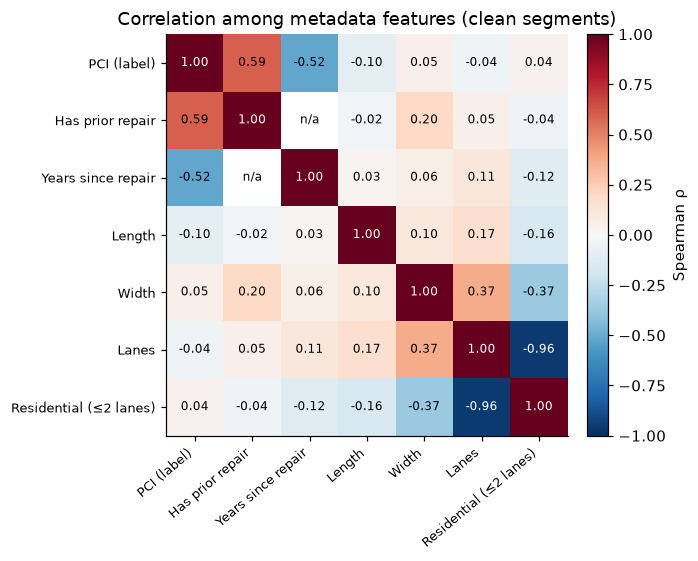

Feature pairs with |rho| >= 0.5:
Lanes  Residential (≤2 lanes)   -0.96


In [8]:
# EDA Cell 5 — Figure 5: Spearman correlation among metadata features and the label
cols = ["pci23", "has_prior_repair", "years_since_repair", "pav_length", "pwidth", "lane_no", "is_residential"]
names = {"pci23": "PCI (label)", "has_prior_repair": "Has prior repair",
         "years_since_repair": "Years since repair", "pav_length": "Length", "pwidth": "Width",
         "lane_no": "Lanes", "is_residential": "Residential (≤2 lanes)"}
C = clean[cols].corr(method="spearman").rename(index=names, columns=names)  # pairwise, ignores blanks

fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)          # diverging: blue -, white 0, red +
ax.set_xticks(range(len(C)), C.columns, rotation=40, ha="right", fontsize=8.5)
ax.set_yticks(range(len(C)), C.index, fontsize=8.5)
for i in range(len(C)):
    for j in range(len(C)):
        v = C.values[i, j]
        txt = "n/a" if np.isnan(v) else f"{v:.2f}"
        ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                color="white" if (not np.isnan(v) and abs(v) > 0.6) else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Spearman ρ")
ax.set_title("Correlation among metadata features (clean segments)")
fig.tight_layout()
fig.savefig(FIG / "fig5_feature_correlation.png", dpi=200)
plt.show()

# Feature pairs that are strongly related (redundancy to handle in the models)
feat_only = C.drop(index="PCI (label)", columns="PCI (label)")
upper = feat_only.where(np.triu(np.ones(feat_only.shape), 1).astype(bool)).stack()
print("Feature pairs with |rho| >= 0.5:")
print(upper[upper.abs() >= 0.5].round(2).sort_values(key=abs, ascending=False).to_string())

Pilot segments: 41 in file | matched: 41 | clean: 25


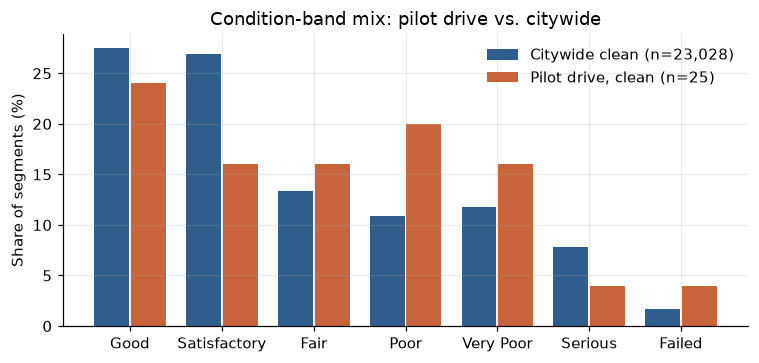

              citywide_%  pilot_%  pilot_n
pci23_d                                   
Good                27.5     24.0        6
Satisfactory        26.9     16.0        4
Fair                13.4     16.0        4
Poor                10.9     20.0        5
Very Poor           11.8     16.0        4
Serious              7.8      4.0        1
Failed               1.7      4.0        1

Pilot clean PCI: mean 59.8, SD 27.1 | citywide clean: mean 65.7, SD 25.9


In [9]:
# EDA Cell 6 — Figure 6: condition-band mix of the pilot drive vs. all clean segments citywide
ORDER = ["Good", "Satisfactory", "Fair", "Poor", "Very Poor", "Serious", "Failed"]
pilot_raw = pd.read_csv(PROC / "gate0_segments_10-25-2026-Mira-Mesa.csv")
id_candidates = [c for c in ["iamfloc", "seg_key", "segment_id"] if c in pilot_raw.columns]
assert id_candidates, f"No segment-ID column found; columns are: {list(pilot_raw.columns)}"
id_col = id_candidates[0]

pilot = df[df["iamfloc"].isin(pilot_raw[id_col])]
pilot_clean = pilot[pilot["in_clean_set"] == 1]
print(f"Pilot segments: {len(pilot_raw)} in file | matched: {len(pilot)} | clean: {len(pilot_clean)}")

city_share = clean["pci23_d"].value_counts(normalize=True).reindex(ORDER).fillna(0) * 100
pilot_share = pilot_clean["pci23_d"].value_counts(normalize=True).reindex(ORDER).fillna(0) * 100

x, w = np.arange(len(ORDER)), 0.38
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(x - w / 2 - 0.01, city_share, w, color=BLUE, label=f"Citywide clean (n={len(clean):,})")
ax.bar(x + w / 2 + 0.01, pilot_share, w, color=ORANGE, label=f"Pilot drive, clean (n={len(pilot_clean)})")
ax.set_xticks(x, ORDER)
ax.set(ylabel="Share of segments (%)", title="Condition-band mix: pilot drive vs. citywide")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig6_pilot_vs_citywide_bands.png", dpi=200)
plt.show()

print(pd.DataFrame({"citywide_%": city_share.round(1), "pilot_%": pilot_share.round(1),
                    "pilot_n": pilot_clean["pci23_d"].value_counts().reindex(ORDER).fillna(0).astype(int)}))
print(f"\nPilot clean PCI: mean {pilot_clean['pci23'].mean():.1f}, SD {pilot_clean['pci23'].std():.1f} "
      f"| citywide clean: mean {clean['pci23'].mean():.1f}, SD {clean['pci23'].std():.1f}")

### Checkpoint 5 — Relationships among features and the driven sample

- **Feature redundancy (Fig. 5):** the only strong pair is lanes vs. residential (Spearman −0.96),
  because residential is defined from lane count; lanes is used as a feature and residential only as a
  filter for the primary analysis set, never both in one model. Width and lanes are moderately related
  (+0.37, width includes parking and shoulders); wider streets were somewhat more often repaired
  (+0.20). Remaining overlap is mild and handled by ridge regularization.
- **Pilot vs. population (Fig. 6):** the 25 clean pilot segments span all seven bands with a similar
  spread to the citywide clean set (SD 27.1 vs. 25.9) but lean toward Poor and Very Poor (36% vs. 23%),
  lowering the mean (59.8 vs. 65.7). This is intentional routing toward damaged streets so the model
  sees enough of them; the trade-off is a non-representative sample, so results will be reported per
  band and the final driven distribution documented once collection is complete.
- **Overall:** the label is well-defined and broadly distributed; repair history is the strongest
  metadata signal, physical attributes carry little; planning area explains a modest 9% of variance;
  and the planned five-area collection is feasible from the clean residential pool.